In [1]:
import numpy as np                              # vectors, cross products, arrays of particles
import matplotlib.pyplot as plt                 # static plots: trajectories, energy, μ, histograms
from matplotlib.animation import FuncAnimation  # animated orbits (save as .gif/.mp4)
from mpl_toolkits.mplot3d import Axes3D         # 3D axes (older Matplotlib versions only)

Constant B no E-field 

E0 = 0.2
E at origin: [0.2 0.  0. ]
B at origin: [0. 0. 1.]
Drift speed: theory -0.2000   measured -0.2009


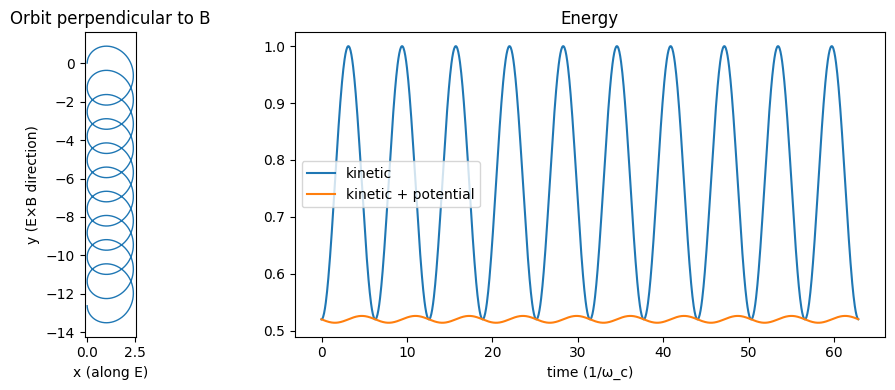

final velocity: [-0.05389966  0.9987889   0.2       ]
final position: [-1.36391429e-04 -1.26139299e+01  1.25600000e+01]


In [2]:
"""
step1_gyration.py — Step 1: gyration in a uniform magnetic field.

Checks the Boris pusher against theory:
  * Larmor radius   r_L   = m v_perp / (|q| B)
  * gyro-period     T     = 2 pi m / (|q| B)
  * kinetic energy  stays constant
"""
import numpy as np                              # vectors, cross products, arrays of particles
import matplotlib.pyplot as plt                 # static plots: trajectories, energy, μ, histograms
from matplotlib.animation import FuncAnimation  # animated orbits (save as .gif/.mp4)
from mpl_toolkits.mplot3d import Axes3D         # 3D axes (older Matplotlib versions only)
%run fields.ipynb
%run pusher.ipynb

# ---- parameters (normalized units) ----
q, m, B0, E0 = 1.0, 1.0, 1.0, 0.2
q_m = q / m
v_perp, v_par = 1.0, 0.2        # velocity across and along B
dt = 0.05                         # omega_c * dt = 0.05  (keep it <~ 0.1)
n_gyrations = 10
omega_c = abs(q) * B0 / m
n_steps = int(n_gyrations * 2 * np.pi / omega_c / dt)

x0 = np.array([0.0, 0.0, 0.0])
v0 = np.array([0.0, v_perp, v_par])

# ---- run ----

print("E0 =", E0)
print("E at origin:", uniform_E(E0)(x0, 0))
print("B at origin:", uniform_B(B0)(x0, 0))
t, x, v = run(x0, v0, q_m, uniform_E(E0), uniform_B(B0), dt, n_steps)

# ---- theory ----
r_L_theory = m * v_perp / (abs(q) * B0)
T_theory = 2 * np.pi / omega_c

# ---- E x B checks ----
v_drift_theory = -E0 / B0                       # along y
v_drift_measured = (x[-1, 1] - x[0, 1]) / t[-1]
print(f"Drift speed: theory {v_drift_theory:.4f}   measured {v_drift_measured:.4f}")

KE = 0.5 * m * np.sum(v**2, axis=1)
total = KE - q * E0 * x[:, 0]                   # kinetic + potential

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(x[:, 0], x[:, 1], lw=1)
ax1.set_aspect("equal")                          # no stretching
ax1.set_xlabel("x (along E)"); ax1.set_ylabel("y (E×B direction)")
ax1.set_title("Orbit perpendicular to B")

ax2.plot(t, KE, label="kinetic")
ax2.plot(t, total, label="kinetic + potential")
ax2.set_xlabel("time (1/ω_c)"); ax2.legend()
ax2.set_title("Energy")
plt.tight_layout(); plt.show()
print("final velocity:", v[-1])
print("final position:", x[-1])

TWO PARTICLES CASE: ELECTRON AND A POSITIVE ION OF q=1


ion (q=+1, m=1)          drift = -0.2068   (theory -0.2000)
electron (q=-1, m=0.2)   drift = -0.2041   (theory -0.2000)


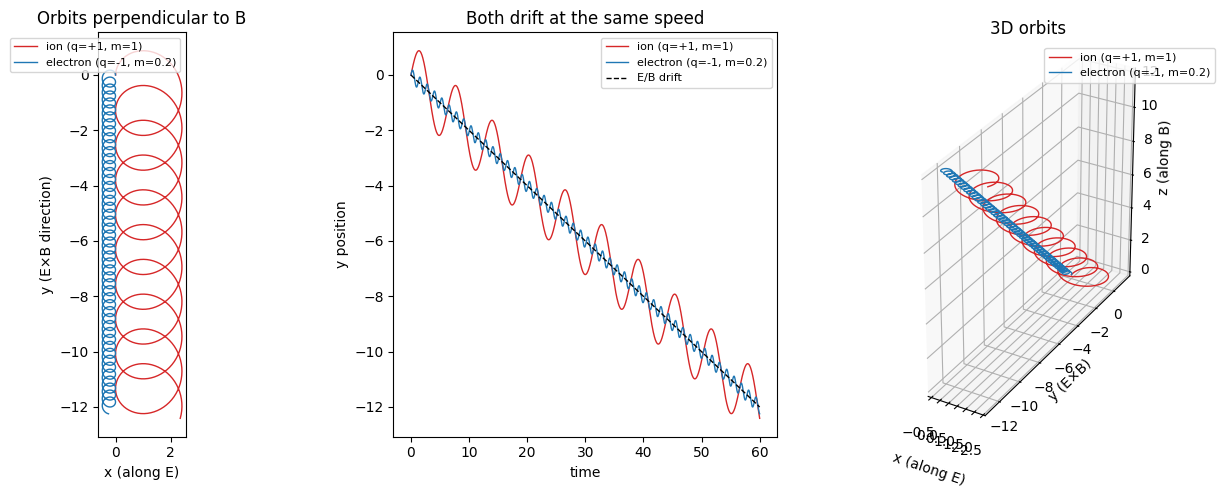

In [3]:

# ---- shared setup ----
B0, E0 = 1.0, 0.2
t_end = 60.0                       # same total time for every particle

# ---- the particles: one dictionary each ----
particles = [
    {"name": "ion (q=+1, m=1)",        "q": +1.0, "m": 1.0, "v_perp": 1.0, "v_par": 0.2, "color": "tab:red"},
    {"name": "electron (q=-1, m=0.2)", "q": -1.0, "m": 0.2, "v_perp": 1.0, "v_par": 0.2, "color": "tab:blue"},
]

fig = plt.figure(figsize=(13, 5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3, projection="3d")
for p in particles:
    q_m = p["q"] / p["m"]
    omega_c = abs(q_m) * B0
    dt = 0.05 / omega_c            # keep omega_c*dt = 0.05 for EACH particle
    n_steps = int(t_end / dt)

    x0 = np.array([0.0, 0.0, 0.0])
    v0 = np.array([0.0, p["v_perp"], p["v_par"]])

    t, x, v = run(x0, v0, q_m, uniform_E(E0), uniform_B(B0), dt, n_steps)

    drift = (x[-1, 1] - x[0, 1]) / t[-1]
    print(f"{p['name']:24s} drift = {drift:+.4f}   (theory {-E0/B0:+.4f})")

    ax1.plot(x[:, 0], x[:, 1], lw=1, color=p["color"], label=p["name"])
    ax2.plot(t, x[:, 1], lw=1, color=p["color"], label=p["name"])
    ax3.plot(x[:, 0], x[:, 1], x[:, 2], lw=1, color=p["color"], label=p["name"])


ax1.set_aspect("equal")
ax1.set_xlabel("x (along E)"); ax1.set_ylabel("y (E×B direction)")
ax1.set_title("Orbits perpendicular to B"); ax1.legend(fontsize=8)

ax2.plot([0, t_end], [0, -E0 / B0 * t_end], "k--", lw=1, label="E/B drift")
ax2.set_xlabel("time"); ax2.set_ylabel("y position")
ax2.set_title("Both drift at the same speed"); ax2.legend(fontsize=8)

ax3.set_box_aspect((np.ptp(ax3.get_xlim()), np.ptp(ax3.get_ylim()), np.ptp(ax3.get_zlim())))
ax3.set_xlabel("x (along E)"); ax3.set_ylabel("y (E×B)"); ax3.set_zlabel("z (along B)")
ax3.set_title("3D orbits"); ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()

Mirror entrappement 

Loss-cone angle: particles with pitch angle < 45.0° escape

α = 70°  (trapped): turning point theory z = ±3.64, measured z = +3.64 / -3.64
           mu varies by 0.0%
α = 46°  (trapped): turning point theory z = ±9.66, measured z = +9.66 / -9.66
           mu varies by 0.1%
α = 26.7°  (escapes): left the mirror at t = 11.7
           mu varies by 0.0%


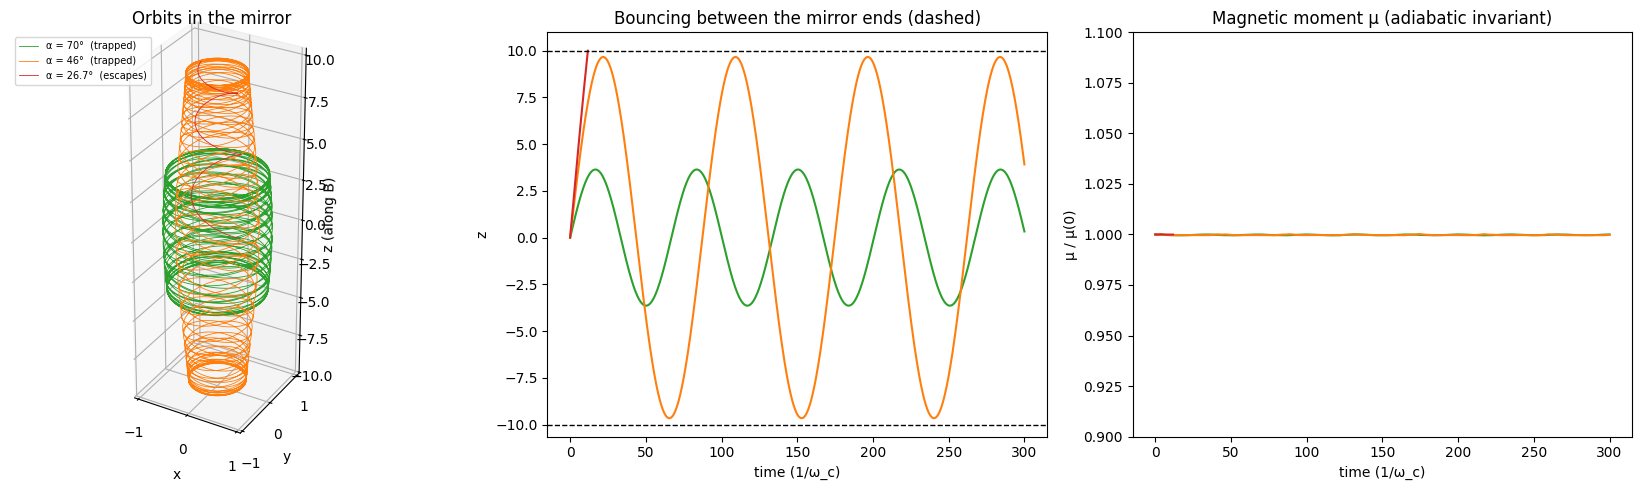

In [4]:

%run fields.ipynb
%run pusher.ipynb

# ---- setup ----
B0, L = 1.0, 10.0          # field at centre, length scale of the mirror
R = 2                          # mirror ratio B_max / B_min
z_end = L * np.sqrt(R - 1)       # the ends are where B = R * B0
q, m = 1.0, 1.0
q_m = q / m
speed = 1.0
dt = 0.02
t_end = 300.0
n_steps = int(t_end / dt)

alpha_crit = np.degrees(np.arcsin(np.sqrt(1 / R)))
print(f"Loss-cone angle: particles with pitch angle < {alpha_crit:.1f}° escape\n")

particles = [
    {"alpha": 70, "color": "tab:green"},
    {"alpha": 46, "color": "tab:orange"},
    {"alpha": 26.7, "color": "tab:red"},
]

fig = plt.figure(figsize=(17, 5))
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3)
B_func = mirror_B(B0, L)

for p in particles:
    a = np.radians(p["alpha"])
    v_perp, v_par = speed * np.sin(a), speed * np.cos(a)
    r_L = m * v_perp / (abs(q) * B0)

    # start ON the gyro-orbit so the guiding centre sits on the axis
    x0 = np.array([r_L, 0.0, 0.0])
    v0 = np.array([0.0, -np.sign(q) * v_perp, v_par])

    t, x, v = run(x0, v0, q_m, zero_E(), B_func, dt, n_steps)

    # cut the trajectory once it leaves the mirror
    out = np.where(np.abs(x[:, 2]) > z_end)[0]
    escaped = len(out) > 0
    if escaped:
        k = out[0]
        t, x, v = t[:k], x[:k], v[:k]

    # magnetic moment mu = m v_perp^2 / (2 B), with v_perp relative to the LOCAL B
    Bvec = np.array([B_func(xi, 0) for xi in x])
    Bmag = np.linalg.norm(Bvec, axis=1)
    v_par_loc = np.sum(v * Bvec, axis=1) / Bmag
    v_perp2 = np.sum(v**2, axis=1) - v_par_loc**2
    mu = m * v_perp2 / (2 * Bmag)

    label = f"α = {p['alpha']}°  ({'escapes' if escaped else 'trapped'})"
    if escaped:
        print(f"{label}: left the mirror at t = {t[-1]:.1f}")
    else:
        print(f"{label}: turning point theory z = ±{L / np.tan(a):.2f}, "
              f"measured z = {x[:, 2].max():+.2f} / {x[:, 2].min():+.2f}")
    print(f"           mu varies by {100*(mu.max()-mu.min())/mu.mean():.1f}%")

    ax1.plot(x[:, 0], x[:, 1], x[:, 2], lw=0.6, color=p["color"], label=label)
    ax2.plot(t, x[:, 2], color=p["color"], label=label)
    ax3.plot(t, mu / mu[0], color=p["color"], label=label)

ax1.set_box_aspect((1, 1, 3))
ax1.set_xticks([-1, 0, 1]); ax1.set_yticks([-1, 0, 1])
ax1.set_xlabel("x"); ax1.set_ylabel("y"); ax1.set_zlabel("z (along B)")
ax1.set_title("Orbits in the mirror"); ax1.legend(fontsize=7, loc="upper left")

ax2.axhline(+z_end, color="k", ls="--", lw=1); ax2.axhline(-z_end, color="k", ls="--", lw=1)
ax2.set_xlabel("time (1/ω_c)"); ax2.set_ylabel("z")
ax2.set_title("Bouncing between the mirror ends (dashed)")

ax3.set_xlabel("time (1/ω_c)"); ax3.set_ylabel("μ / μ(0)")
ax3.set_ylim(0.9, 1.1)
ax3.set_title("Magnetic moment μ (adiabatic invariant)")

plt.tight_layout()
plt.show()

Escaped: 28.1%   (theory 29.3%)


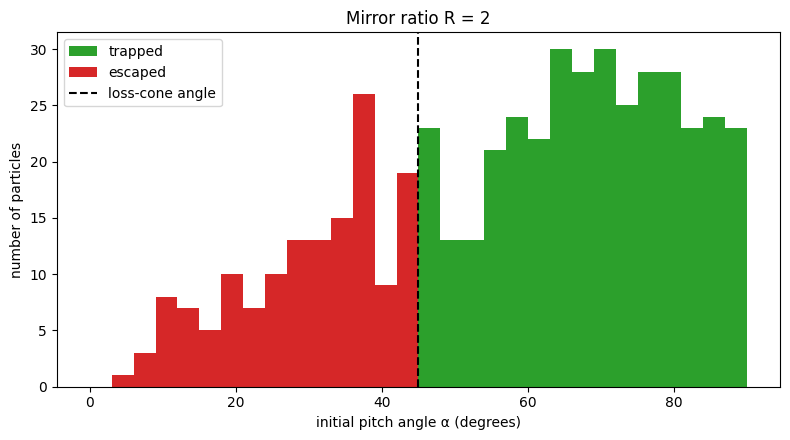

In [5]:

import random
B0, L = 1.0, 10.0          # field at centre, length scale of the mirror
R = 2                          # mirror ratio B_max / B_min
z_end = L * np.sqrt(R - 1)       # the ends are where B = R * B0
speed = 1.0
dt = 0.02
t_end = 300.0
n_steps = int(t_end / dt)

particleslist = []  
for N in range(1000):
    alpha = float(np.degrees(np.arccos(random.random())))
    num = random.random()
    if num <= 0.5:
        particleslist.append({"name": "electron", "q": -1.0, "m": 0.2, "alpha":alpha})
    
    if num > 0.5:
        particleslist.append({"name": "ion", "q": +1.0, "m": 1.0, "alpha":alpha})

t_end = 60.0                     # long enough: escaping particles leave on the first pass
n_steps = int(t_end / dt)
B_func = mirror_B(B0, L)


for p in particleslist: 
    q, m = p["q"], p["m"]
    q_m = q / m
    a = np.radians(p["alpha"])
    v_perp, v_par = speed * np.sin(a), speed * np.cos(a)
    r_L = m * v_perp / (abs(q) * B0)

    # start ON the gyro-orbit so the guiding centre sits on the axis
    x0 = np.array([r_L, 0.0, 0.0])
    v0 = np.array([0.0, -np.sign(q) * v_perp, v_par])

    t, x, v = run(x0, v0, q_m, zero_E(), B_func, dt, n_steps)
    p["escaped"] = bool(np.any(np.abs(x[:, 2]) > z_end))

    # cut the trajectory once it leaves the mirror
    out = np.where(np.abs(x[:, 2]) > z_end)[0]
    escaped = len(out) > 0
    if escaped:
        k = out[0]
        t, x, v = t[:k], x[:k], v[:k]

    # magnetic moment mu = m v_perp^2 / (2 B), with v_perp relative to the LOCAL B
    Bvec = np.array([B_func(xi, 0) for xi in x])
    Bmag = np.linalg.norm(Bvec, axis=1)
    v_par_loc = np.sum(v * Bvec, axis=1) / Bmag
    v_perp2 = np.sum(v**2, axis=1) - v_par_loc**2
    mu = m * v_perp2 / (2 * Bmag)

    label = f"α = {p['alpha']}°  ({'escapes' if escaped else 'trapped'})"
    ##if escaped:
     #   print(f"{label}: left the mirror at t = {t[-1]:.1f}")
    #else:
    #    print(f"{label}: turning point theory z = ±{L / np.tan(a):.2f}, "
    #          f"measured z = {x[:, 2].max():+.2f} / {x[:, 2].min():+.2f}")
    #print(f"           mu varies by {100*(mu.max()-mu.min())/mu.mean():.1f}%")


alphas  = np.array([p["alpha"]   for p in particleslist])
escaped = np.array([p["escaped"] for p in particleslist])
names = np.array([p["name"] for p in particleslist])

print(f"Escaped: {escaped.mean()*100:.1f}%   (theory {100*(1-np.sqrt(1-1/R)):.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, 90, 31)

ax.hist(alphas[(~escaped) & (names == "electron")], bins=bins, color="tab:green", label="trapped")
ax.hist(alphas[(escaped) & (names == "electron")],  bins=bins, color="tab:red",   label="escaped")
ax.axvline(np.degrees(np.arcsin(np.sqrt(1/R))), color="k", ls="--", label="loss-cone angle")
ax.set_xlabel("initial pitch angle α (degrees)"); ax.set_ylabel("number of particles")
ax.set_title(f"Mirror ratio R = {R}"); ax.legend()
plt.tight_layout(); plt.show()

LOSS CONE GRAPH + AI-OPTIMISED CODE ABOVE --> WAY FASTER

1000 particles, 6000 steps in 0.4 s
Escaped: 27.2%   (theory 29.3%)


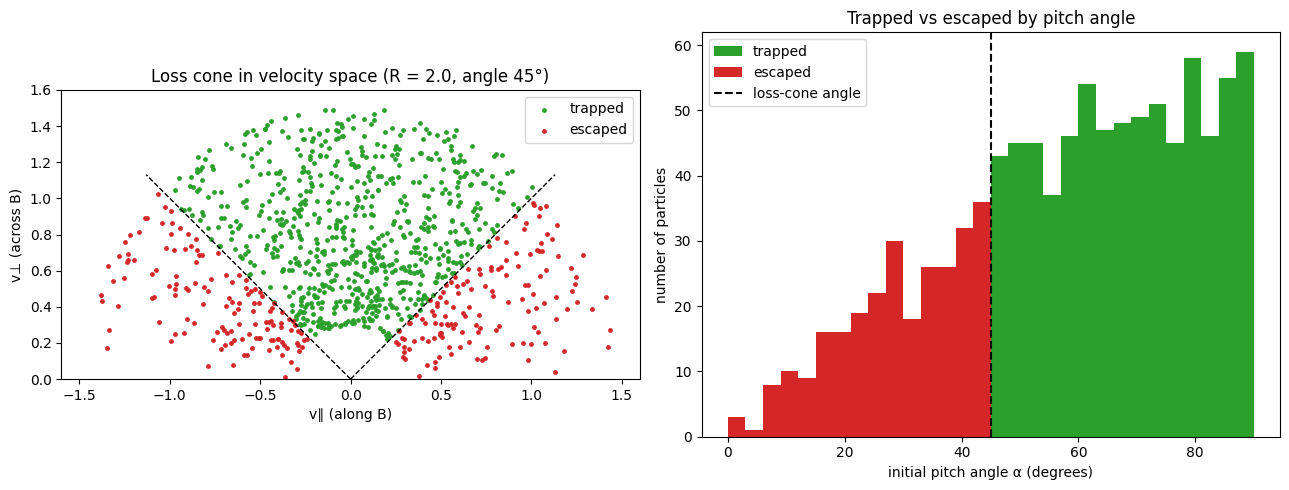

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ---- vectorized pieces: x and v have shape (N, 3), one row per particle ----
def mirror_B_many(B0=1.0, L=10.0):
    def B(x, t):
        X, Y, Z = x[..., 0], x[..., 1], x[..., 2]          # works for (3,) and (N, 3)
        return B0 * np.stack([-X * Z / L**2,
                              -Y * Z / L**2,
                              1 + Z**2 / L**2], axis=-1)
    return B

def boris_step_many(x, v, q_m, E, B, dt):
    """Same Boris step, but for N particles at once. q_m has shape (N, 1)."""
    v_minus = v + q_m * E * dt / 2
    t = q_m * B * dt / 2
    s = 2 * t / (1 + np.sum(t * t, axis=1, keepdims=True))
    v_prime = v_minus + np.cross(v_minus, t)
    v_plus = v_minus + np.cross(v_prime, s)
    v_new = v_plus + q_m * E * dt / 2
    return x + v_new * dt, v_new

# ---- setup ----
rng = np.random.default_rng()
N = 1000
B0, L, R = 1.0, 10.0, 2.0
z_end = L * np.sqrt(R - 1)
dt, t_end = 0.02, 120.0
n_steps = int(t_end / dt)

is_electron = rng.random(N) < 0.5
q = np.where(is_electron, -1.0, 1.0)
m = np.where(is_electron, 0.2, 1.0)
alpha = np.degrees(np.arccos(rng.random(N)))     # isotropic pitch angles

speed = rng.uniform(0.3, 1.5, N)                 # different speeds for each particle
sign = rng.choice([-1, 1], N)                    # half move up (+z), half down (-z)
a = np.radians(alpha)
v_perp, v_par = speed * np.sin(a), sign * speed * np.cos(a)
r_L = m * v_perp / (np.abs(q) * B0)

x = np.zeros((N, 3)); x[:, 0] = r_L
v = np.zeros((N, 3)); v[:, 1] = -np.sign(q) * v_perp; v[:, 2] = v_par
q_m = (q / m)[:, None]                           # shape (N, 1) so it broadcasts over x, y, z

B_func = mirror_B_many(B0, L)
E = np.zeros((N, 3))
escaped = np.zeros(N, dtype=bool)

# ---- run: the loop is over TIME only; all particles move together ----
start = time.time()
for i in range(n_steps):
    x, v = boris_step_many(x, v, q_m, E, B_func(x, i * dt), dt)
    escaped |= np.abs(x[:, 2]) > z_end
print(f"{N} particles, {n_steps} steps in {time.time() - start:.1f} s")
print(f"Escaped: {escaped.mean()*100:.1f}%   (theory {100*(1-np.sqrt(1-1/R)):.1f}%)")

# ---- velocity-space picture of the loss cone ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(v_par[~escaped], v_perp[~escaped], s=6, c="tab:green", label="trapped")
ax1.scatter(v_par[escaped],  v_perp[escaped],  s=6, c="tab:red",   label="escaped")
a_lc = np.arcsin(np.sqrt(1 / R))                 # loss-cone angle
vmax = 1.6
for sgn in (+1, -1):                             # the two cone edges
    ax1.plot([0, sgn * vmax * np.cos(a_lc)], [0, vmax * np.sin(a_lc)], "k--", lw=1)
ax1.set_xlabel("v∥ (along B)"); ax1.set_ylabel("v⊥ (across B)")
ax1.set_aspect("equal"); ax1.set_xlim(-vmax, vmax); ax1.set_ylim(0, vmax)
ax1.set_title(f"Loss cone in velocity space (R = {R}, angle {np.degrees(a_lc):.0f}°)")
ax1.legend(loc="upper right")

bins = np.linspace(0, 90, 31)
ax2.hist(alpha[~escaped], bins=bins, color="tab:green", label="trapped")
ax2.hist(alpha[escaped],  bins=bins, color="tab:red",   label="escaped")
ax2.axvline(np.degrees(a_lc), color="k", ls="--", label="loss-cone angle")
ax2.set_xlabel("initial pitch angle α (degrees)"); ax2.set_ylabel("number of particles")
ax2.set_title("Trapped vs escaped by pitch angle"); ax2.legend()

plt.tight_layout()
plt.savefig("step4_loss_cone_vspace.png", dpi=110)
plt.show()

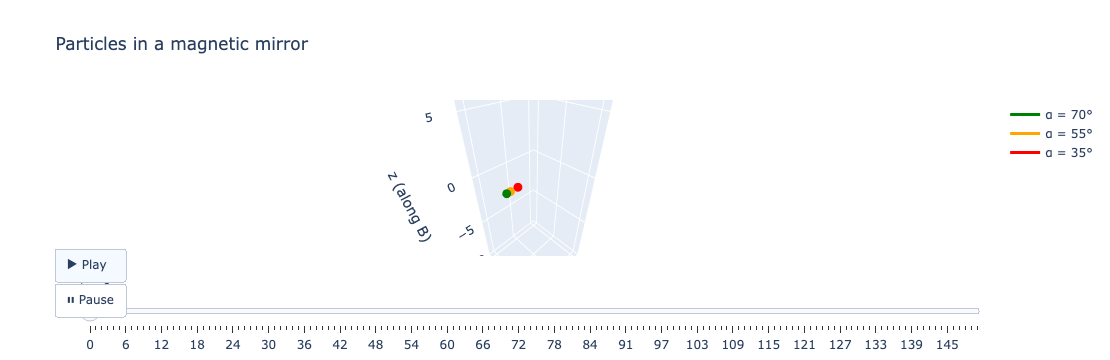

In [8]:
import plotly.graph_objects as go
%run fields.ipynb
%run pusher.ipynb


# ---- 1. simulate (same as step 3) ----
B0, L = 1.0, 10.0
R = 2.0
z_end = L * np.sqrt(R - 1)
dt, t_end = 0.02, 150.0
n_steps = int(t_end / dt)
B_func = mirror_B(B0, L)

runs = []
for alpha, color in [(70, "green"), (55, "orange"), (35, "red")]:
    a = np.radians(alpha)
    v_perp, v_par = np.sin(a), np.cos(a)
    x0 = np.array([v_perp, 0.0, 0.0])
    v0 = np.array([0.0, -v_perp, v_par])
    t, x, v = run(x0, v0, 1.0, zero_E(), B_func, dt, n_steps)
    out = np.where(np.abs(x[:, 2]) > z_end)[0]
    if len(out) > 0:
        x = x[: out[0] + 1]
    runs.append({"x": x[::10], "name": f"α = {alpha}°", "color": color})   # keep every 10th point

# ---- 2. pick which time steps become animation frames ----
n_points = len(runs[0]["x"])            # points kept per trajectory
n_frames = 150
idx = np.linspace(0, n_points - 1, n_frames).astype(int)

def traces_at(k):
    """Everything drawn at frame k: a trail up to now + a dot at the current position."""
    out = []
    for r in runs:
        x = r["x"][: k + 1]
        out.append(go.Scatter3d(x=x[:, 0], y=x[:, 1], z=x[:, 2], mode="lines",
                                line=dict(color=r["color"], width=3), name=r["name"]))
        out.append(go.Scatter3d(x=[x[-1, 0]], y=[x[-1, 1]], z=[x[-1, 2]], mode="markers",
                                marker=dict(color=r["color"], size=5), showlegend=False))
    return out

# ---- 3. build the figure: first frame + one frame per time step ----
fig = go.Figure(
    data=traces_at(idx[0]),
    frames=[go.Frame(data=traces_at(k), name=str(k)) for k in idx],
)

# ---- 4. play/pause buttons and a time slider ----
fig.update_layout(
    title="Particles in a magnetic mirror",
    scene=dict(xaxis=dict(range=[-1.2, 1.2]), yaxis=dict(range=[-1.2, 1.2]),
               zaxis=dict(range=[-L, L], title="z (along B)"),
               aspectmode="manual", aspectratio=dict(x=1, y=1, z=3)),
    updatemenus=[dict(type="buttons", x=0.05, y=0.05, buttons=[
        dict(label="▶ Play", method="animate",
             args=[None, dict(frame=dict(duration=40, redraw=True), fromcurrent=True)]),
        dict(label="⏸ Pause", method="animate",
             args=[[None], dict(frame=dict(duration=0), mode="immediate")]),
    ])],
    sliders=[dict(currentvalue=dict(prefix="t = "), steps=[
        dict(label=f"{k * 10 * dt:.0f}", method="animate",
             args=[[str(k)], dict(frame=dict(duration=0, redraw=True), mode="immediate")])
        for k in idx
    ])],
)

fig.write_html("mirror_animation.html")   # open in any browser
fig.show()                               # shows it inside Jupyter

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
%run fields.ipynb
%run pusher.ipynb


L = 10.0          # length scale of the mirror field
speed = 1.0       # particle speed (normalized)
m = 1.0           # mass (normalized)

def simulate_and_plot(scenario, charge, B0, alpha, E0, R):
    q = 1.0 if charge == "+ ion" else -1.0
    q_m = q / m
    a = np.radians(alpha)
    v_perp, v_par = speed * np.sin(a), speed * np.cos(a)
    r_L = m * v_perp / (abs(q) * B0)

    x0 = np.array([r_L, 0.0, 0.0])                    # guiding centre on the z-axis
    v0 = np.array([0.0, -np.sign(q) * v_perp, v_par])
    color = "tab:red" if q > 0 else "tab:blue"

    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(1, 2, 1, projection="3d")
    ax2 = fig.add_subplot(1, 2, 2)

    if scenario == "Uniform (E×B)":
        omega_c = abs(q_m) * B0
        dt = 0.05 / omega_c
        n_steps = int(10 * 2 * np.pi / omega_c / dt)      # always 10 gyrations
        t, x, v = run(x0, v0, q_m, uniform_E(E0), uniform_B(B0), dt, n_steps)

        drift = (x[-1, 1] - x[0, 1]) / t[-1]
        info = (f"r_L = {r_L:.3f}     E×B drift: theory {-E0/B0:+.3f},"
                f" measured {drift:+.3f}")

        ax2.plot(x[:, 0], x[:, 1], color=color, lw=1)
        ax2.set_aspect("equal")
        ax2.set_xlabel("x (along E)"); ax2.set_ylabel("y (E×B)")
        ax2.set_title("View along B")

    else:  # magnetic mirror
        z_end = L * np.sqrt(R - 1)                       # wall where B = R * B0
        dt = 0.1 / (abs(q_m) * B0 * R)
        n_steps = int(120 / dt)
        t, x, v = run(x0, v0, q_m, zero_E(), mirror_B(B0, L), dt, n_steps)

        out = np.where(np.abs(x[:, 2]) > z_end)[0]      # cut where it leaves
        escaped = len(out) > 0
        if escaped:
            t, x, v = t[: out[0] + 1], x[: out[0] + 1], v[: out[0] + 1]

        loss_cone = np.degrees(np.arcsin(np.sqrt(1 / R)))
        if escaped:
            info = f"loss cone {loss_cone:.1f}°   →   ESCAPED at t = {t[-1]:.1f}"
        else:
            info = (f"loss cone {loss_cone:.1f}°   →   TRAPPED, turning point "
                    f"theory ±{L/np.tan(a):.2f}, measured {x[:, 2].max():.2f}")

        ax2.plot(t, x[:, 2], color=color)
        ax2.axhline(+z_end, color="gray", ls="--"); ax2.axhline(-z_end, color="gray", ls="--")
        ax2.set_xlabel("time (1/ω_c)"); ax2.set_ylabel("z")
        ax2.set_title("Bounce motion (dashed = mirror ends)")

    step = max(1, len(t) // 5000)                         # thin out points for speed
    ax1.plot(x[::step, 0], x[::step, 1], x[::step, 2], color=color, lw=0.8)
    ranges = np.ptp(x, axis=0) + 1e-9                     # true size along x, y, z
    ax1.set_box_aspect(np.minimum(ranges, 3 * ranges.min()))   # true shape, but stretch at most 3x
    ax1.locator_params(nbins=4)
    ax1.set_xlabel("x"); ax1.set_ylabel("y"); ax1.set_zlabel("z (along B)")
    ax1.set_title("3D trajectory")

    fig.suptitle(info)
    plt.tight_layout()
    plt.show()

# ---- the sliders ----
style = {"description_width": "150px"}
wide = widgets.Layout(width="500px")
widgets.interact(
    simulate_and_plot,
    scenario=widgets.ToggleButtons(options=["Uniform (E×B)", "Magnetic mirror"]),
    charge=widgets.ToggleButtons(options=["+ ion", "− electron"]),
    B0=widgets.FloatSlider(1.0, min=0.2, max=5.0, step=0.1, description="B₀",
                           continuous_update=False, style=style, layout=wide),
    alpha=widgets.IntSlider(60, min=1, max=90, description="pitch angle α (°)",
                            continuous_update=False, style=style, layout=wide),
    E0=widgets.FloatSlider(0.2, min=-0.5, max=0.5, step=0.05, description="E (uniform only)",
                           continuous_update=False, style=style, layout=wide),
    R=widgets.FloatSlider(2.0, min=1.0, max=10.0, step=0.1, description="R (mirror only)",
                          continuous_update=False, style=style, layout=wide),
)

interactive(children=(ToggleButtons(description='scenario', options=('Uniform (E×B)', 'Magnetic mirror'), valu…

<function __main__.simulate_and_plot(scenario, charge, B0, alpha, E0, R)>